#Project Title
##Income, Employment and Education Analysis

## Project Goal

To analyze the Adult Income dataset using Python to explore how demographic, educational, and employment-related factors are associated with income levels, identify patterns and relationships in the data, and present meaningful insights through data analysis and visualization.

## Project Objectives

- To analyze the relationship between education and income levels.
- To examine how employment-related factors such as workclass, occupation, and working hours are associated with income.
- To study the influence of demographic factors such as age, marital status, sex, and race on income categories.
- To identify important patterns and relationships between education, employment, demographics, and income.
- To summarize the key findings using statistical analysis and data visualizations.


## 1.Importing Libraries

The following Python libraries are used in this project for data manipulation, numerical calculations, and data visualization.

* **Pandas:** Used to load, clean, organize, and analyze the dataset.
* **NumPy:** Used for numerical operations and calculations.
* **Matplotlib:** Used to create charts and graphs for data visualization.
* **Seaborn:** Used to create statistical visualizations and explore relationships between variables.
* **Plotly:** Used to create interaractive charts and visualizations.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

## Dataset Information

| Attribute       | Value                           |
| --------------- | ------------------------------- |
| Source          | UCI Machine Learning Repository |
| Original Source | 1994 U.S. Census Database       |
| Records         | 32,561 individuals              |
| Features        | 14 input features               |
| Total Columns   | 15 (including target)           |
| Target Variable | Income (<=50K / >50K)           |
| Data Types      | Numerical and Categorical       |
| Analysis Type   | Exploratory Data Analysis (EDA) |

**Dataset Link:** https://archive.ics.uci.edu/dataset/2/adult

## 2. Data Loading

The dataset is loaded into Python using Pandas. The data is read from the `adult.data` file and stored in a DataFrame named `df` for further analysis.

In [2]:
import zipfile

with zipfile.ZipFile("/content/adult.zip") as z:
    df = pd.read_csv(
        z.open("adult.data"),
        header=None,
        skipinitialspace=True
    )

df.head()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


## 3. Dataset Columns

The Adult Income dataset contains 15 columns, including demographic, educational, employment, financial, and income-related information.

**1. Demographic Information**
 age,race,sex, native_country

**2. Employment Information**
 workclass,occupation,hours_per_week

**3. Education Information**
 education,education_num

**4. Personal Information**
 marital_status,relationship

**5. Financial Information**
 fnlwgt,capital_gain,capital_loss

**6. Target Variable**
 income


In [3]:
df.columns = [
    "age", "workclass", "fnlwgt", "education",
    "education_num", "marital_status", "occupation",
    "relationship", "race", "sex",
    "capital_gain", "capital_loss",
    "hours_per_week", "native_country", "income"
]

## 4. Initial Data Overview

The initial data overview helps us understand the structure, size, column names, and data types of the dataset before starting preprocessing and analysis.

In [4]:
# First five rows
df.head()

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [5]:
# Dataset dimensions
df.shape

(32561, 15)

In [6]:
# Column names
df.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'education_num',
       'marital_status', 'occupation', 'relationship', 'race', 'sex',
       'capital_gain', 'capital_loss', 'hours_per_week', 'native_country',
       'income'],
      dtype='object')

In [7]:
# Data types and information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education_num   32561 non-null  int64 
 5   marital_status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital_gain    32561 non-null  int64 
 11  capital_loss    32561 non-null  int64 
 12  hours_per_week  32561 non-null  int64 
 13  native_country  32561 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


In [8]:
# Statistical summary
df.describe()

,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


## 5. Data Preprocessing

Data preprocessing is the process of identifying and handling missing values, duplicate records, inconsistent data, incorrect data types, and invalid values to improve data quality before analysis.

### 5.1 Checking Missing Values

The dataset is checked for missing values in two forms: null values (`isnull`) and question mark (`?`) values. The missing values in each column are identified to understand the completeness of the dataset.

In [9]:
# Check missing values
df.isnull().sum()

,0
age,0
workclass,0
fnlwgt,0
education,0
education_num,0
marital_status,0
occupation,0
relationship,0
race,0
sex,0


In [10]:
(df == "?").sum()

,0
age,0
workclass,1836
fnlwgt,0
education,0
education_num,0
marital_status,0
occupation,1843
relationship,0
race,0
sex,0


### 5.2 Handling Missing Values

The question mark `?` values in the workclass, occupation, and native_country columns are replaced with `Unknown` so that these records can be retained for analysis.

In [11]:
df = df.replace("?", "Unknown")
(df == "Unknown").sum()


,0
age,0
workclass,1836
fnlwgt,0
education,0
education_num,0
marital_status,0
occupation,1843
relationship,0
race,0
sex,0


### 5.3 Removing Duplicate Records

Duplicate records were identified in the dataset. These repeated rows are removed to avoid counting the same record more than once during analysis.

In [12]:
df.duplicated().sum()

np.int64(24)

In [13]:
df=df.drop_duplicates()


In [14]:
df.duplicated().sum(),df.shape

(np.int64(0), (32537, 15))

### 5.4 Checking Data Types

The data types of all columns are checked to understand whether the variables are stored in appropriate formats for further analysis.

In [15]:
df.dtypes

,0
age,int64
workclass,object
fnlwgt,int64
education,object
education_num,int64
marital_status,object
occupation,object
relationship,object
race,object
sex,object


In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 32537 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32537 non-null  int64 
 1   workclass       32537 non-null  object
 2   fnlwgt          32537 non-null  int64 
 3   education       32537 non-null  object
 4   education_num   32537 non-null  int64 
 5   marital_status  32537 non-null  object
 6   occupation      32537 non-null  object
 7   relationship    32537 non-null  object
 8   race            32537 non-null  object
 9   sex             32537 non-null  object
 10  capital_gain    32537 non-null  int64 
 11  capital_loss    32537 non-null  int64 
 12  hours_per_week  32537 non-null  int64 
 13  native_country  32537 non-null  object
 14  income          32537 non-null  object
dtypes: int64(6), object(9)
memory usage: 4.0+ MB


**Observation:** The dataset contains 6 numerical columns (`int64`) and 9 categorical columns (`object`). The data types are suitable for the next stage of data analysis.

### 5.5 Checking Invalid Values

Invalid values are checked to identify data entries that may be incorrect or outside the expected range. The age, hours_per_week, capital_gain, and capital_loss columns are examined to identify unusual or potentially invalid values.

In [17]:
df["age"].describe()

,age
count,32537.000000
mean,38.585549
std,13.637984
min,17.000000
25%,28.000000
50%,37.000000
75%,48.000000
max,90.000000


In [18]:
df["hours_per_week"].describe()

,hours_per_week
count,32537.000000
mean,40.440329
std,12.346889
min,1.000000
25%,40.000000
50%,40.000000
75%,45.000000
max,99.000000


In [19]:
df["capital_gain"].describe()

,capital_gain
count,32537.000000
mean,1078.443741
std,7387.957424
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,99999.000000


In [20]:
df["capital_loss"].describe()

,capital_loss
count,32537.000000
mean,87.368227
std,403.101833
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,4356.000000


For the age column, the valid range was considered to be 17 to 90 based on the observed minimum and maximum values in the dataset. Therefore, values below 17 or above 90 were considered potentially invalid and reviewed.



In [21]:
print("Invalid age:")
print(df[(df["age"] < 17) | (df["age"] > 90)])

print("Invalid working hours:")
print(df[(df["hours_per_week"] < 1) |
         (df["hours_per_week"] > 99)])

print("Negative capital gain:")
print(df[df["capital_gain"] < 0])

print("Negative capital loss:")
print(df[df["capital_loss"] < 0])

Invalid age:
Empty DataFrame
Columns: [age, workclass, fnlwgt, education, education_num, marital_status, occupation, relationship, race, sex, capital_gain, capital_loss, hours_per_week, native_country, income]
Index: []
Invalid working hours:
Empty DataFrame
Columns: [age, workclass, fnlwgt, education, education_num, marital_status, occupation, relationship, race, sex, capital_gain, capital_loss, hours_per_week, native_country, income]
Index: []
Negative capital gain:
Empty DataFrame
Columns: [age, workclass, fnlwgt, education, education_num, marital_status, occupation, relationship, race, sex, capital_gain, capital_loss, hours_per_week, native_country, income]
Index: []
Negative capital loss:
Empty DataFrame
Columns: [age, workclass, fnlwgt, education, education_num, marital_status, occupation, relationship, race, sex, capital_gain, capital_loss, hours_per_week, native_country, income]
Index: []


### 5.6 Checking Inconsistent Values

Inconsistent values are checked to identify differences in spelling, extra spaces, or formatting in categorical columns. The `native_country` column is examined to identify values that may need standardization.

In [22]:
# Check unique country values

df["native_country"].value_counts()

,count
native_country,
United-States,29153
Mexico,639
Unknown,582
Philippines,198
Germany,137
Canada,121
Puerto-Rico,114
El-Salvador,106
India,100


### 5.6.1 Handling Inconsistent Values

The native_country column is standardized by removing extra spaces and standardizing selected country labels. This helps maintain consistent category names for analysis.


In [23]:
# Remove extra spaces
df["native_country"] = df["native_country"].str.strip()

# Standardize selected country labels
df['native_country'] = df['native_country'].replace({
    'Columbia': 'Colombia',
    'Trinadad&Tobago': 'Trinidad&Tobago',
    'Holand-Netherlands': 'Netherlands',
    'Hong': 'Hong Kong'
})
# Check updated country values
df["native_country"].value_counts()

,count
native_country,
United-States,29153
Mexico,639
Unknown,582
Philippines,198
Germany,137
Canada,121
Puerto-Rico,114
El-Salvador,106
India,100


# 6. Checking Outliers

Outliers are unusually high or low values in a dataset. The Interquartile Range (IQR) method is used to identify potential outliers in numerical columns. The lower and upper limits are calculated,and the number of outliers is counted before deciding how to handle them.

In [24]:
columns = ["age", "hours_per_week", "capital_gain", "capital_loss"]

for col in columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print("Column:", col)
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower limit:", lower)
    print("Upper limit:", upper)
    print("Number of outliers:", len(outliers))
    print("-------------------------")

Column: age
Q1: 28.0
Q3: 48.0
IQR: 20.0
Lower limit: -2.0
Upper limit: 78.0
Number of outliers: 142
-------------------------
Column: hours_per_week
Q1: 40.0
Q3: 45.0
IQR: 5.0
Lower limit: 32.5
Upper limit: 52.5
Number of outliers: 9002
-------------------------
Column: capital_gain
Q1: 0.0
Q3: 0.0
IQR: 0.0
Lower limit: 0.0
Upper limit: 0.0
Number of outliers: 2712
-------------------------
Column: capital_loss
Q1: 0.0
Q3: 0.0
IQR: 0.0
Lower limit: 0.0
Upper limit: 0.0
Number of outliers: 1519
-------------------------


### 6.1 Outlier Analysis


The IQR method identified potential outliers in the selected numerical columns. The original dataset contains 142 potential outliers in age, 9,002 in hours_per_week, 2,712 in capital_gain, and 1,519 in capital_loss. These potential outliers were reviewed because some extreme values may represent valid observations, so they were retained for further analysis.


###6.2 Checking Missing Values

After checking the data for outliers, the dataset is checked for any remaining missing values. This step ensures that the data is complete and ready for further analysis.


In [25]:
df.isnull().sum()

,0
age,0
workclass,0
fnlwgt,0
education,0
education_num,0
marital_status,0
occupation,0
relationship,0
race,0
sex,0


# 7. Exploratory Data Analysis(EDA)
# 7.1 Univariate Analysis
###7.1.1 Numerical Variables



Univariate analysis is used to study one variable at a time. In this step, histograms and box plots are used to understand the distribution, spread, and possible extreme values of numerical variables.


 ### Histogram


A histogram is used to visualize the distribution of numerical variables. It helps to understand how the values are distributed across different ranges.


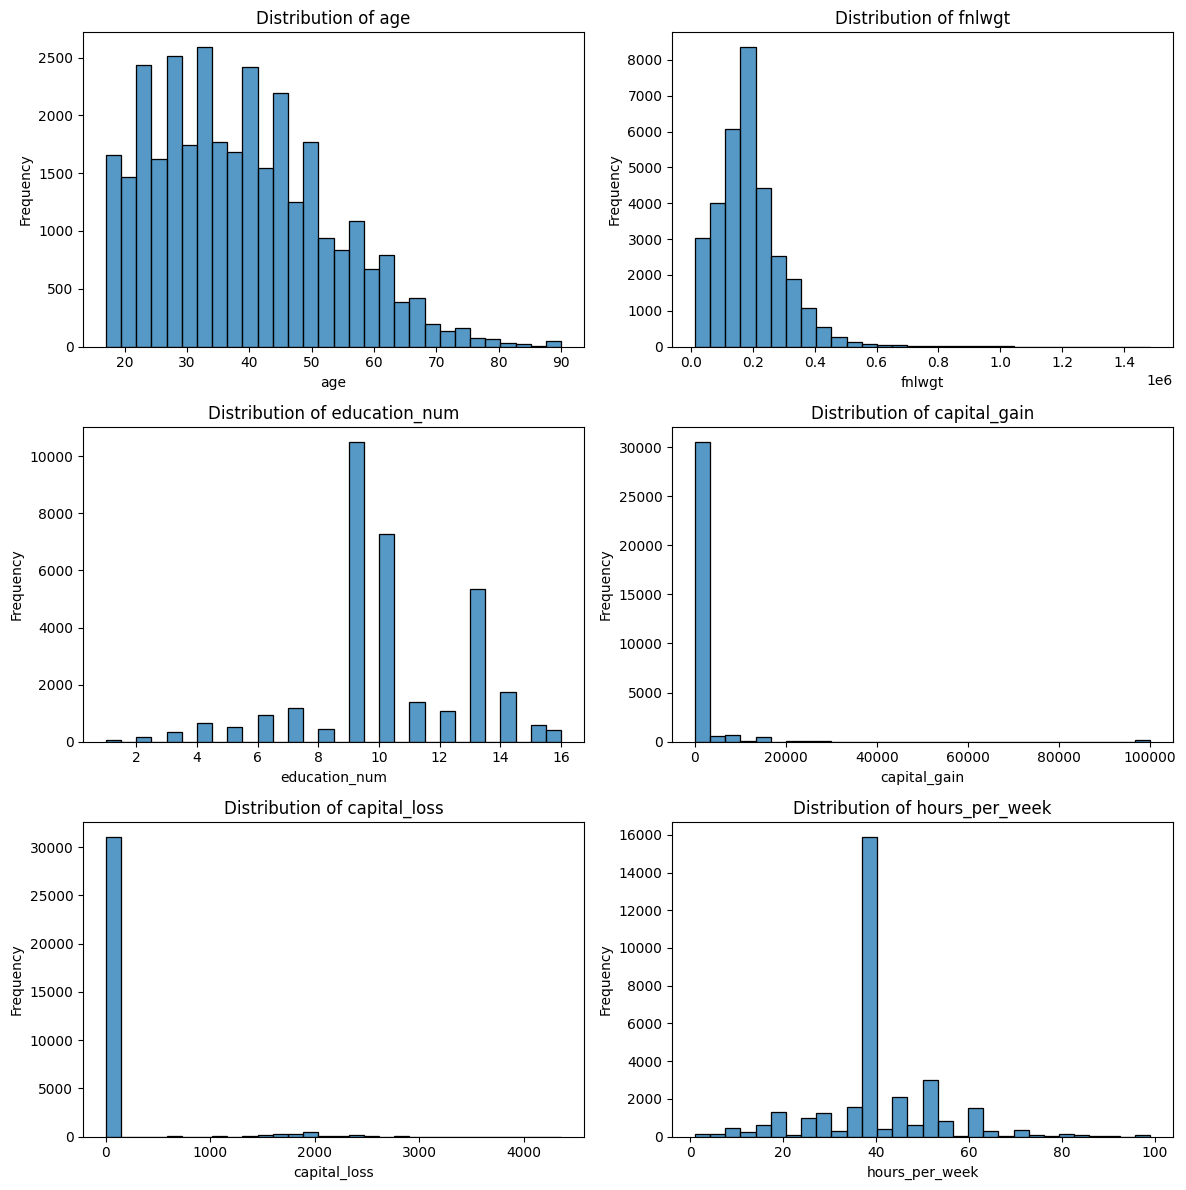

In [26]:
numerical_cols = [ 'age',
                  'fnlwgt',
                   'education_num',
                   'capital_gain',
                   'capital_loss',
                   'hours_per_week' ]

fig, axes = plt.subplots(3, 2, figsize=(12, 12))
axes = axes.flatten()

for i, col in enumerate(numerical_cols):
  sns.histplot(df[col].dropna(), bins=30, kde=False, ax=axes[i])
  axes[i].set_title(f'Distribution of {col}')
  axes[i].set_xlabel(col)
  axes[i].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

The histograms reveal varied distributions among numerical features. age is slightly right-skewed with concentration in the 20-50 year range, while fnlwgt shows strong right-skewness clustered around 0.2 million. education_num exhibits a multimodal distribution with peaks at 9, 10, and 13-14 years, reflecting common education milestones. Both capital_gain and capital_loss are heavily zero-inflated with >90% observations at zero and long right tails, requiring log transformation. hours_per_week shows a unimodal distribution with a dominant peak at 40 hours, indicating standard full-time employment.

### Box Plot

 A box plot is used to understand the spread and distribution of numerical variables. It helps identify the median, quartiles, and potential extreme values in the data.


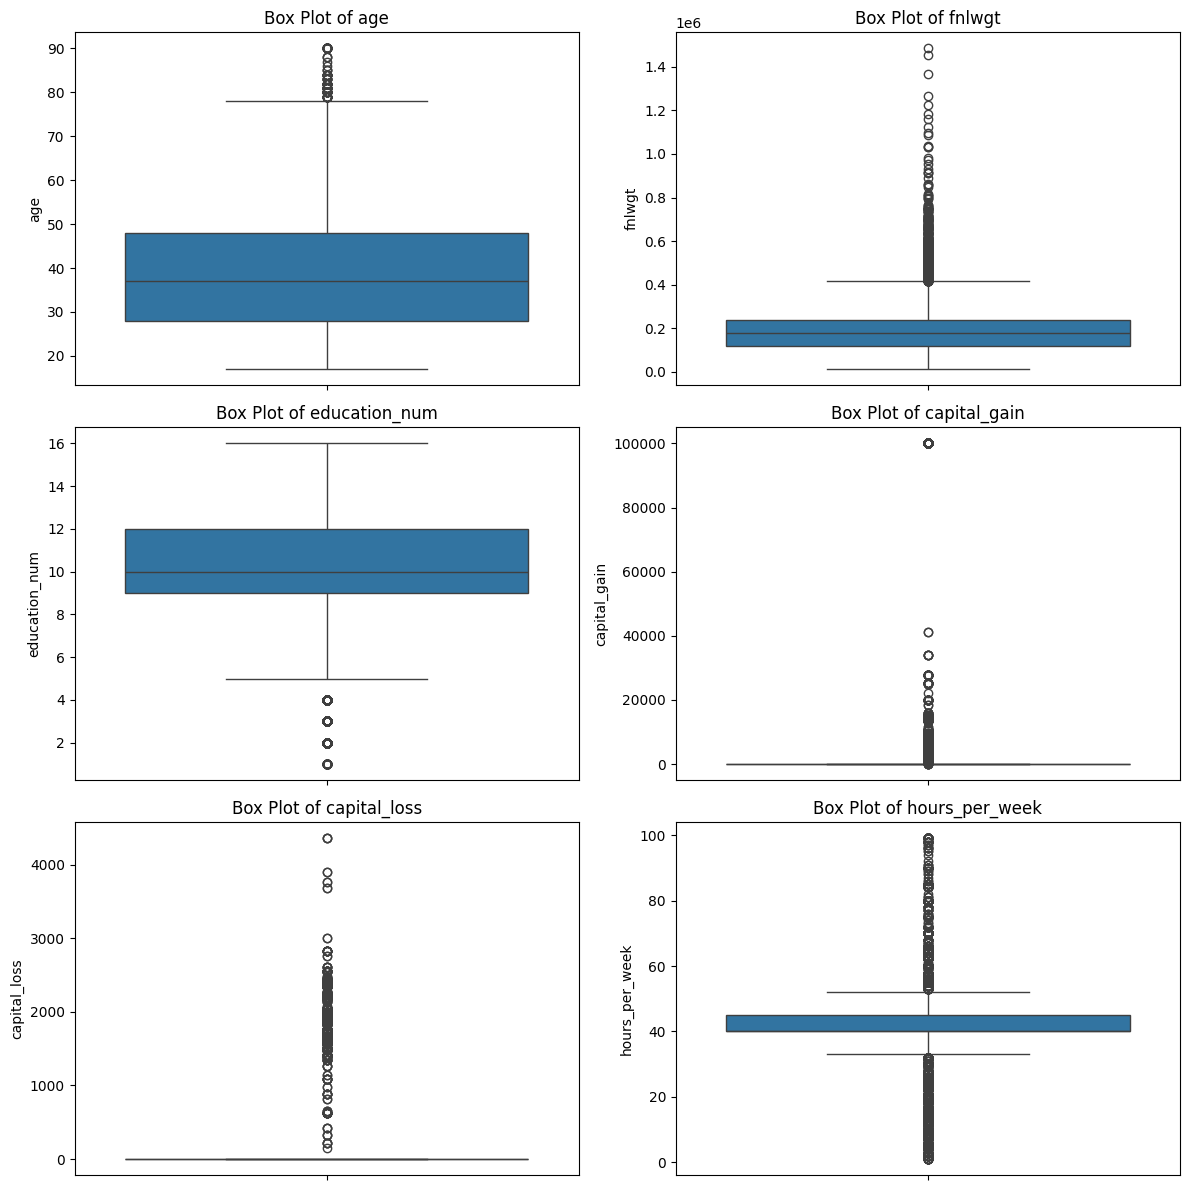

In [27]:
numerical_cols = [
    'age',
    'fnlwgt',
    'education_num',
    'capital_gain',
    'capital_loss',
    'hours_per_week'
]

fig, axes = plt.subplots(3, 2, figsize=(12, 12))
axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    sns.boxplot(y=df[col], ax=axes[i])
    axes[i].set_title('Box Plot of ' + col)
    axes[i].set_ylabel(col)

plt.tight_layout()
plt.show()

Box plots were utilized to examine the distribution and detect potential outliers in the numerical features: age, fnlwgt, education_num, capital_gain, capital_loss, and hours_per_week.
The plots display the median, interquartile range (IQR), and extreme values for each variable. Features such as capital_gain and capital_loss exhibit significant right-skewness with a high number of extreme values, as the majority of observations are concentrated at zero. Similarly, fnlwgt and hours_per_week show notable outliers at both ends. In contrast, age and education_num display relatively balanced distributions with fewer outliers.
Due to varying scales across features, each variable was plotted independently to enhance readability. The identified outliers were retained for further investigation rather than being removed outright, as they may represent valid and meaningful data points.


##7.1.2  Categorical Variables
###Count Plot

 Categorical variables contain values that represent different groups or categories. Count plots are used to show the frequency of observations in each category. This helps to understand the distribution of categorical variables in the dataset.

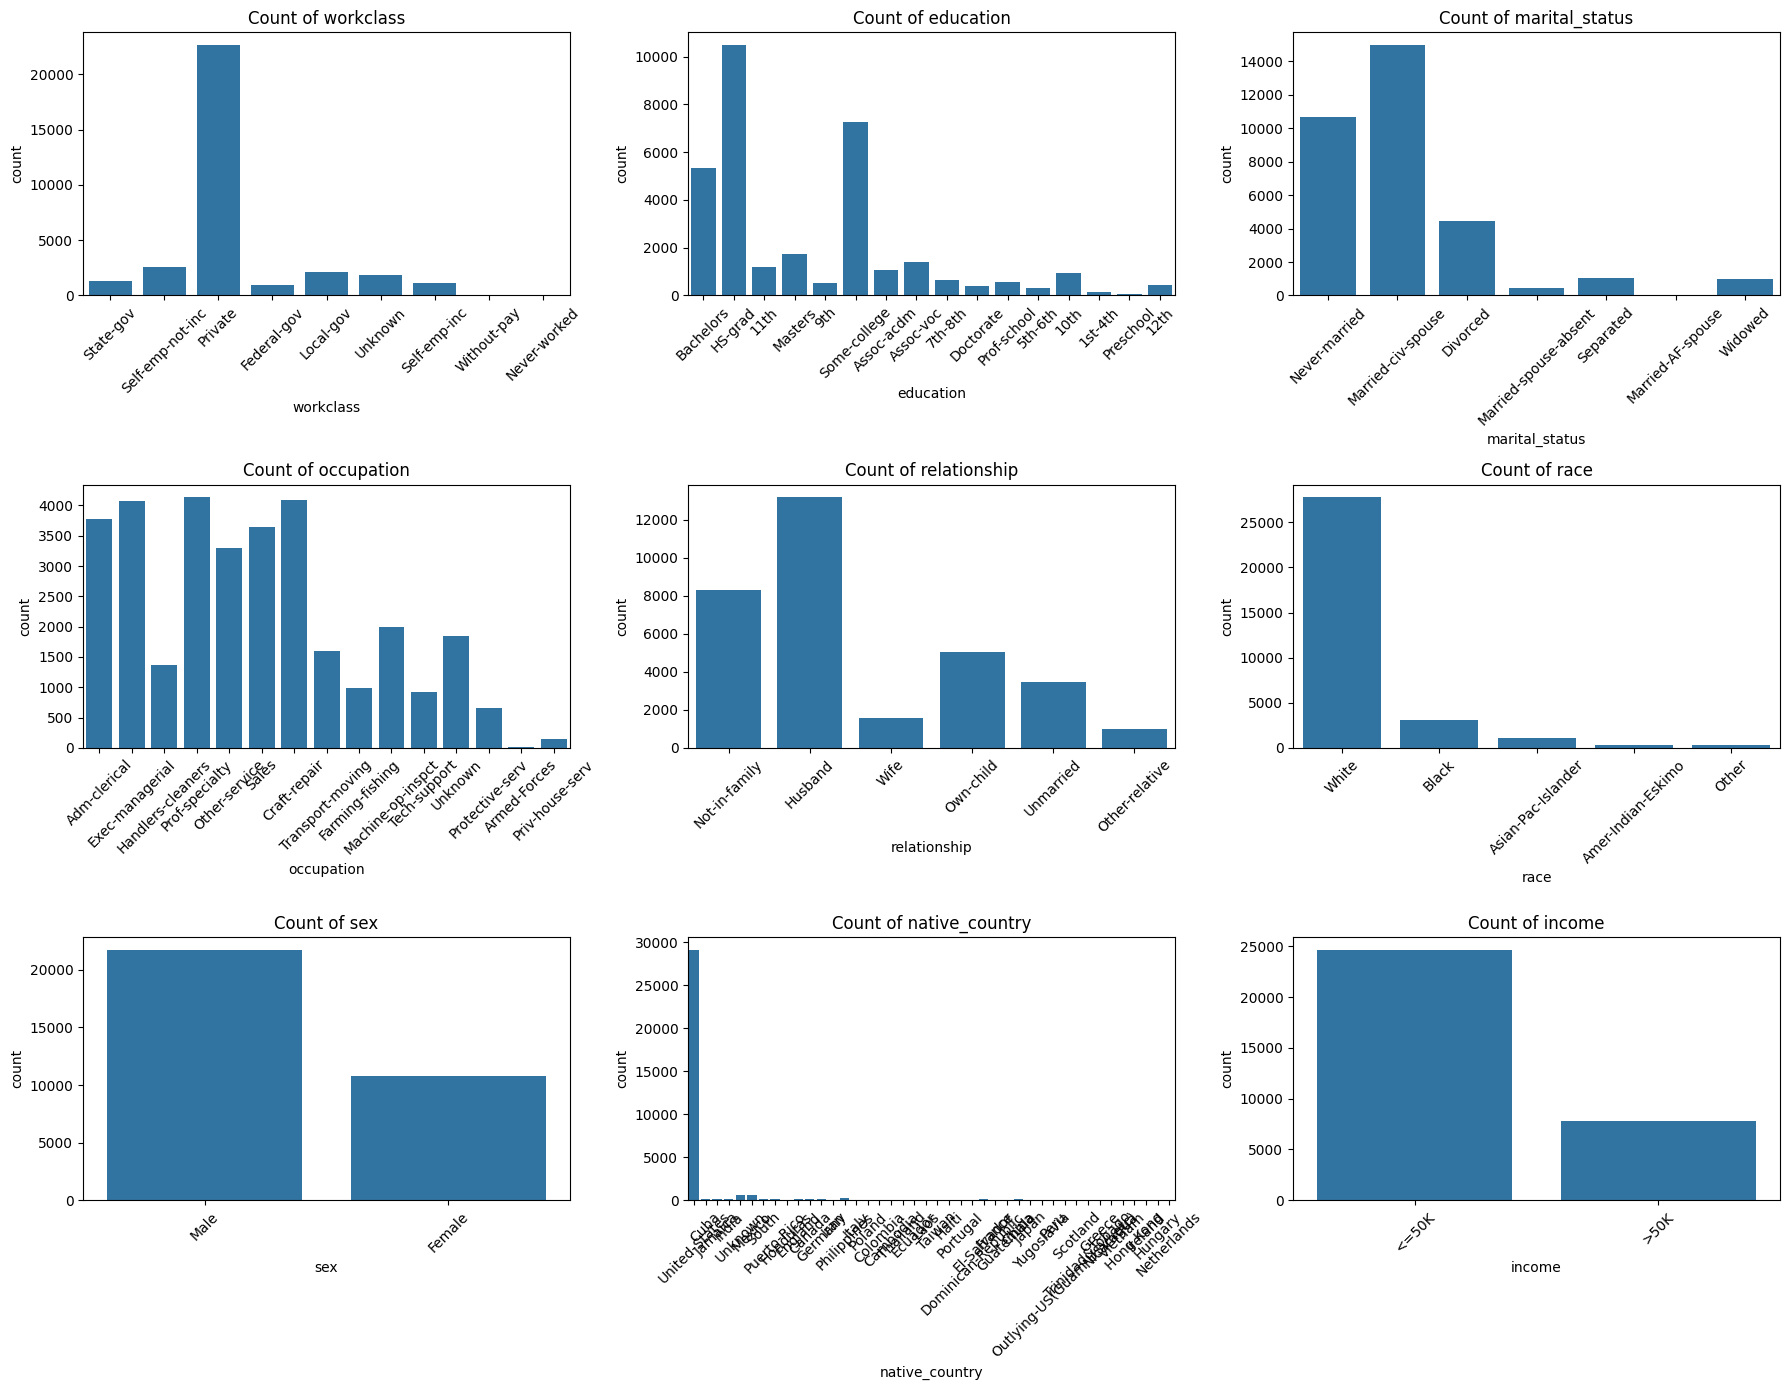

In [28]:
categorical_columns = [
    "workclass", "education", "marital_status",
    "occupation", "relationship", "race",
    "sex", "native_country", "income"
]

fig, axes = plt.subplots(3, 3, figsize=(18, 14))

for ax, col in zip(axes.flat, categorical_columns):
    sns.countplot(data=df, x=col, ax=ax)
    ax.set_title(f"Count of {col}")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

> The count plots show the frequency of observations across different categorical variables. The dataset contains more observations in the private workclass compared with other workclass categories. In education, Bachelor’s degree and High School-related categories have relatively higher frequencies. The marital status is mainly concentrated in the Married-civ-spouse and Never-married categories. The relationship category is mainly represented by Husband and Not-in-family. White is the most frequent race category, and Male observations are higher than Female observations. The income category shows that most observations belong to the <=50K group, while fewer observations belong to the >50K group.

###Bar Plot*

A bar plot is used to compare the frequency of different categories. It provides a clear visual comparison of the most common and least common categories within a categorical variable.

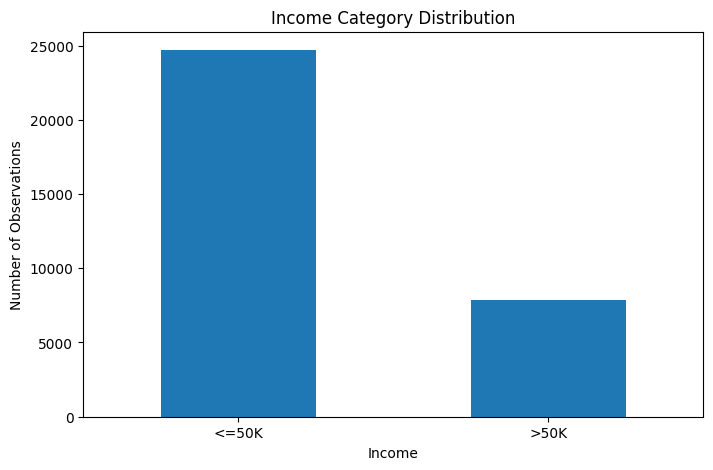

In [29]:
income_counts = df["income"].value_counts()

plt.figure(figsize=(8, 5))
income_counts.plot(kind="bar")

plt.title("Income Category Distribution")
plt.xlabel("Income")
plt.ylabel("Number of Observations")
plt.xticks(rotation=0)
plt.show()

The bar plot shows the distribution of income categories in the dataset. The number of individuals with income <=50K is considerably higher than those with income >50K. This indicates that the dataset is imbalanced towards the <=50K income category.

#7.2 Bivariate Analysis
##7.2.1 Numerical vs Numerical
 ### Scatter Plot
 Bivariate analysis is used to study the relationship between two variables. A scatter plot is used to visualize the relationship between two numerical variables and helps identify patterns, trends, or possible relationships between them.


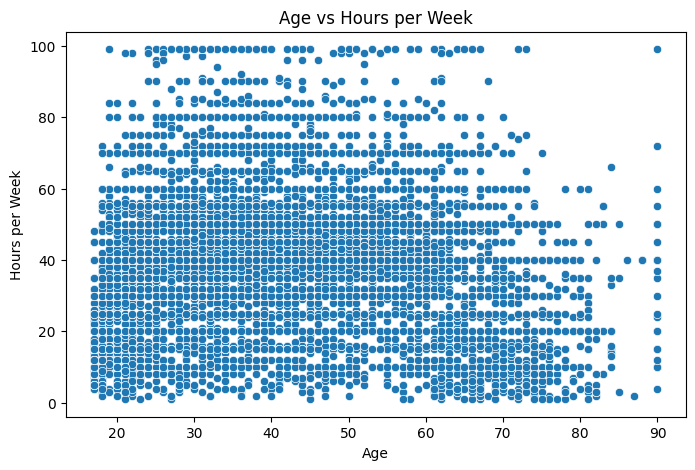

In [30]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="age", y="hours_per_week")

plt.title("Age vs Hours per Week")
plt.xlabel("Age")
plt.ylabel("Hours per Week")
plt.show()

 The scatter plot shows the relationship between age and hours worked per week. The points are widely scattered across different age groups and working hours, indicating that there is no strong linear relationship between age and hours worked per week. Most observations are concentrated around the lower to middle range of working hours, while some observations show higher working hours.


##7.2.2 Categorical vs Numerical
###Box Plot

 A box plot is used to compare the distribution of a numerical variable across different categories. It helps compare the median, spread, and potential extreme values between the groups.


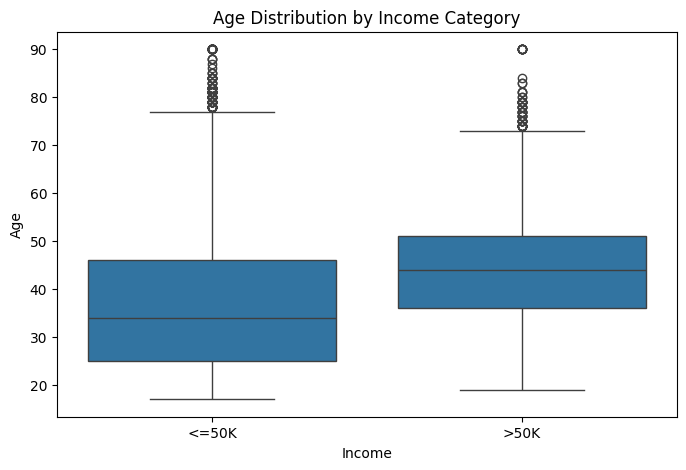

In [31]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="income", y="age")

plt.title("Age Distribution by Income Category")
plt.xlabel("Income")
plt.ylabel("Age")
plt.show()

The box plot compares the age distribution across the two income categories. The >50K income group has a higher median age than the <=50K group. The >50K group is therefore generally concentrated among older individuals. Both groups show some potential extreme values at higher ages.

 ### Bar Plot
A bar plot is used to compare the average value of a numerical variable across different categories. It helps to understand how the numerical variable changes between the groups.


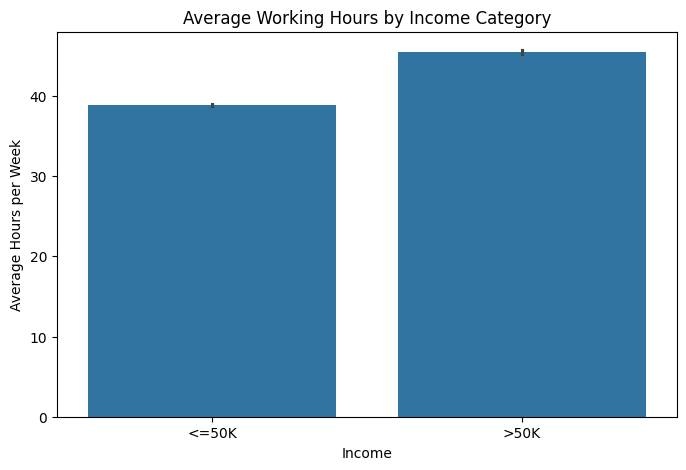

In [32]:
plt.figure(figsize=(8, 5))

sns.barplot(data=df, x="income", y="hours_per_week")

plt.title("Average Working Hours by Income Category")
plt.xlabel("Income")
plt.ylabel("Average Hours per Week")
plt.show()

 The bar plot compares the average working hours across the two income categories. The >50K income group has a higher average number of working hours per week compared with the <=50K income group. This suggests that higher-income individuals tend to work slightly more hours per week on average.


##7.2.3 Categorical vs Categorical
### Count Plot + Cross Tabulation
Categorical vs categorical analysis is used to study the relationship between two categorical variables. A count plot helps visualize the frequency of combinations of categories, while a cross-tabulation shows the corresponding counts in tabular form.

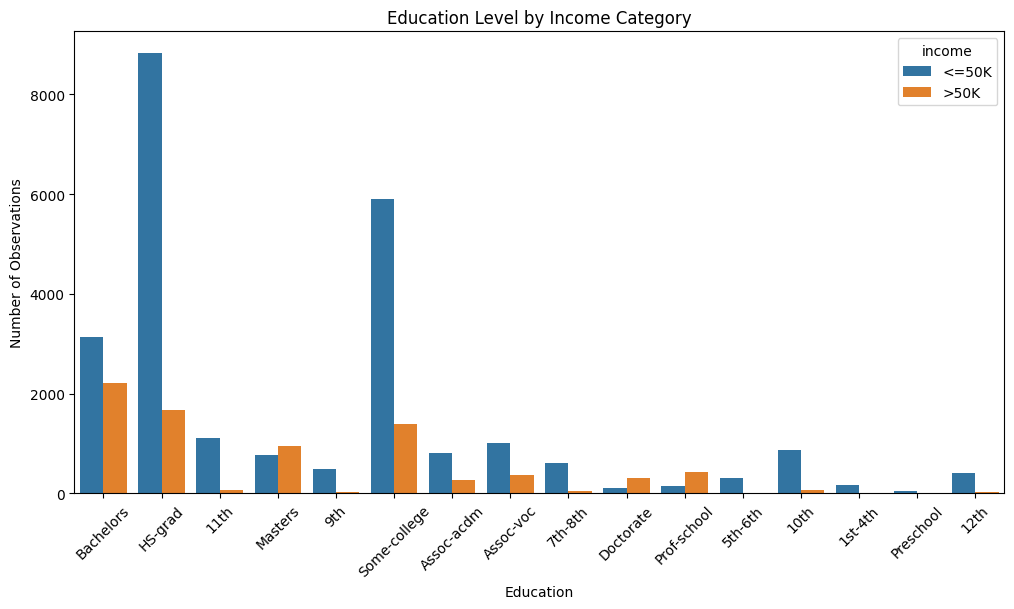

In [33]:
plt.figure(figsize=(12, 6))

sns.countplot(data=df, x="education", hue="income")

plt.title("Education Level by Income Category")
plt.xlabel("Education")
plt.ylabel("Number of Observations")
plt.xticks(rotation=45)
plt.show()

In [34]:
education_income = pd.crosstab(df["education"], df["income"])

education_income


income,<=50K,>50K
education,,
10th,871,62
11th,1115,60
12th,400,33
1st-4th,160,6
5th-6th,316,16
7th-8th,605,40
9th,487,27
Assoc-acdm,802,265
Assoc-voc,1021,361


 The count plot and cross-tabulation show the relationship between education level and income category. Most education categories have more individuals in the <=50K income group than in the >50K group. Higher education levels such as Bachelors, Masters, and Doctorate show a relatively larger number of individuals in the >50K income category compared with lower education levels. This indicates that higher educational attainment is associated with a greater representation in the higher-income group.



# 7.3 Multivariate Analysis
Multivariate analysis is used to study relationships among more than two variables at the same time. It helps to understand how multiple numerical and categorical variables are related and provides deeper insights into patterns within the dataset.


### 7.3.1 Correlation Heatmap
A correlation heatmap is used to visualize the correlation between numerical variables. It helps identify the strength and direction of relationships between the variables.

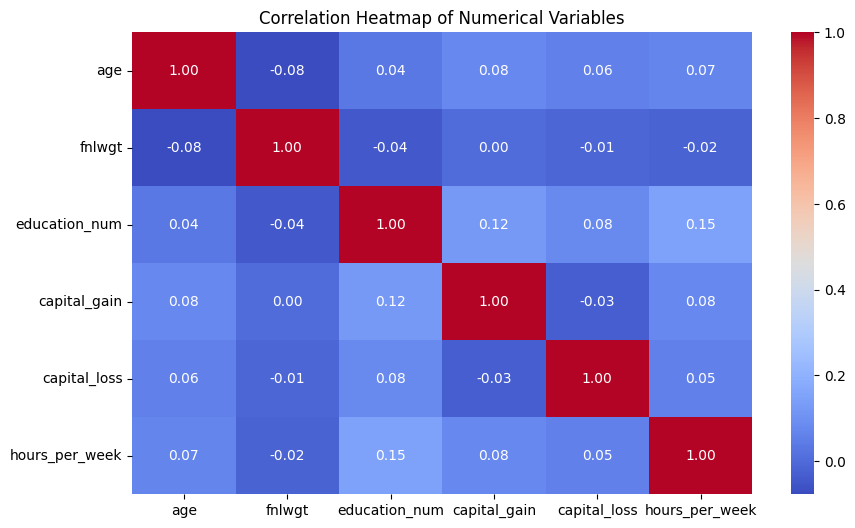

In [35]:
numerical_cols = [
    'age',
    'fnlwgt',
    'education_num',
    'capital_gain',
    'capital_loss',
    'hours_per_week'
]

plt.figure(figsize=(10, 6))

correlation_matrix = df[numerical_cols].corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Numerical Variables")
plt.show()


The correlation heatmap was used to identify the strength and direction of linear relationships between the numerical variables in the dataset.

The highest positive correlation was observed between '**education_num**' and '**hours_per_week**', with a correlation coefficient of approximately **0.15**. This indicates a weak positive relationship between education level and working hours.

The correlation between '**education_num**' and '**capital_gain**' was approximately **0.12**, indicating a weak positive relationship. The remaining correlations were generally close to zero, suggesting weak linear relationships between most numerical variables.

The correlation between '**age**' and '**fnlwgt**' was approximately **-0.08**, showing a very weak negative relationship.

Overall, the heatmap indicates that most numerical variables have weak linear correlations with one another. Correlation does not imply causation.

### 7.3.2 Grouped Visualization
Grouped visualization is used to compare a numerical variable across multiple categorical groups. It helps identify differences in average working hours across income and sex categories.

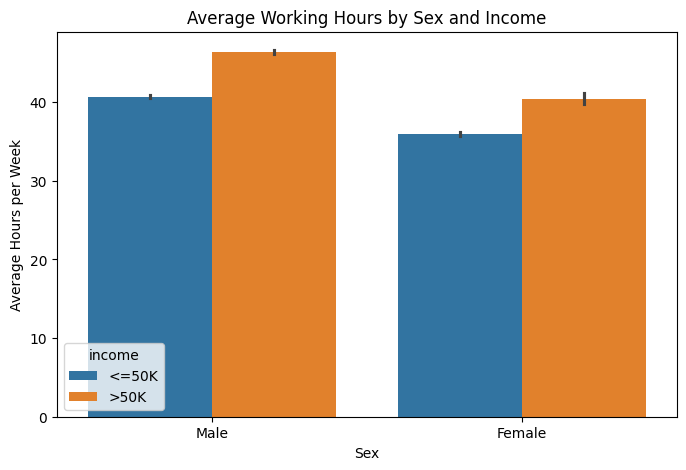

In [36]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="sex",
    y="hours_per_week",
    hue="income"
)

plt.title("Average Working Hours by Sex and Income")
plt.xlabel("Sex")
plt.ylabel("Average Hours per Week")
plt.show()

The grouped bar plot compares average working hours by sex and income category. For both males and females, the >50K income group has higher average working hours per week than the <=50K group. The difference is more noticeable among males, while females show a smaller difference between the two income groups.


### 7.3.3 Pair Plot
A pair plot is used to visualize the relationships between multiple numerical variables. It shows the distribution of each variable and the relationships between pairs of variables. This helps identify patterns, trends, and possible relationships in the dataset.

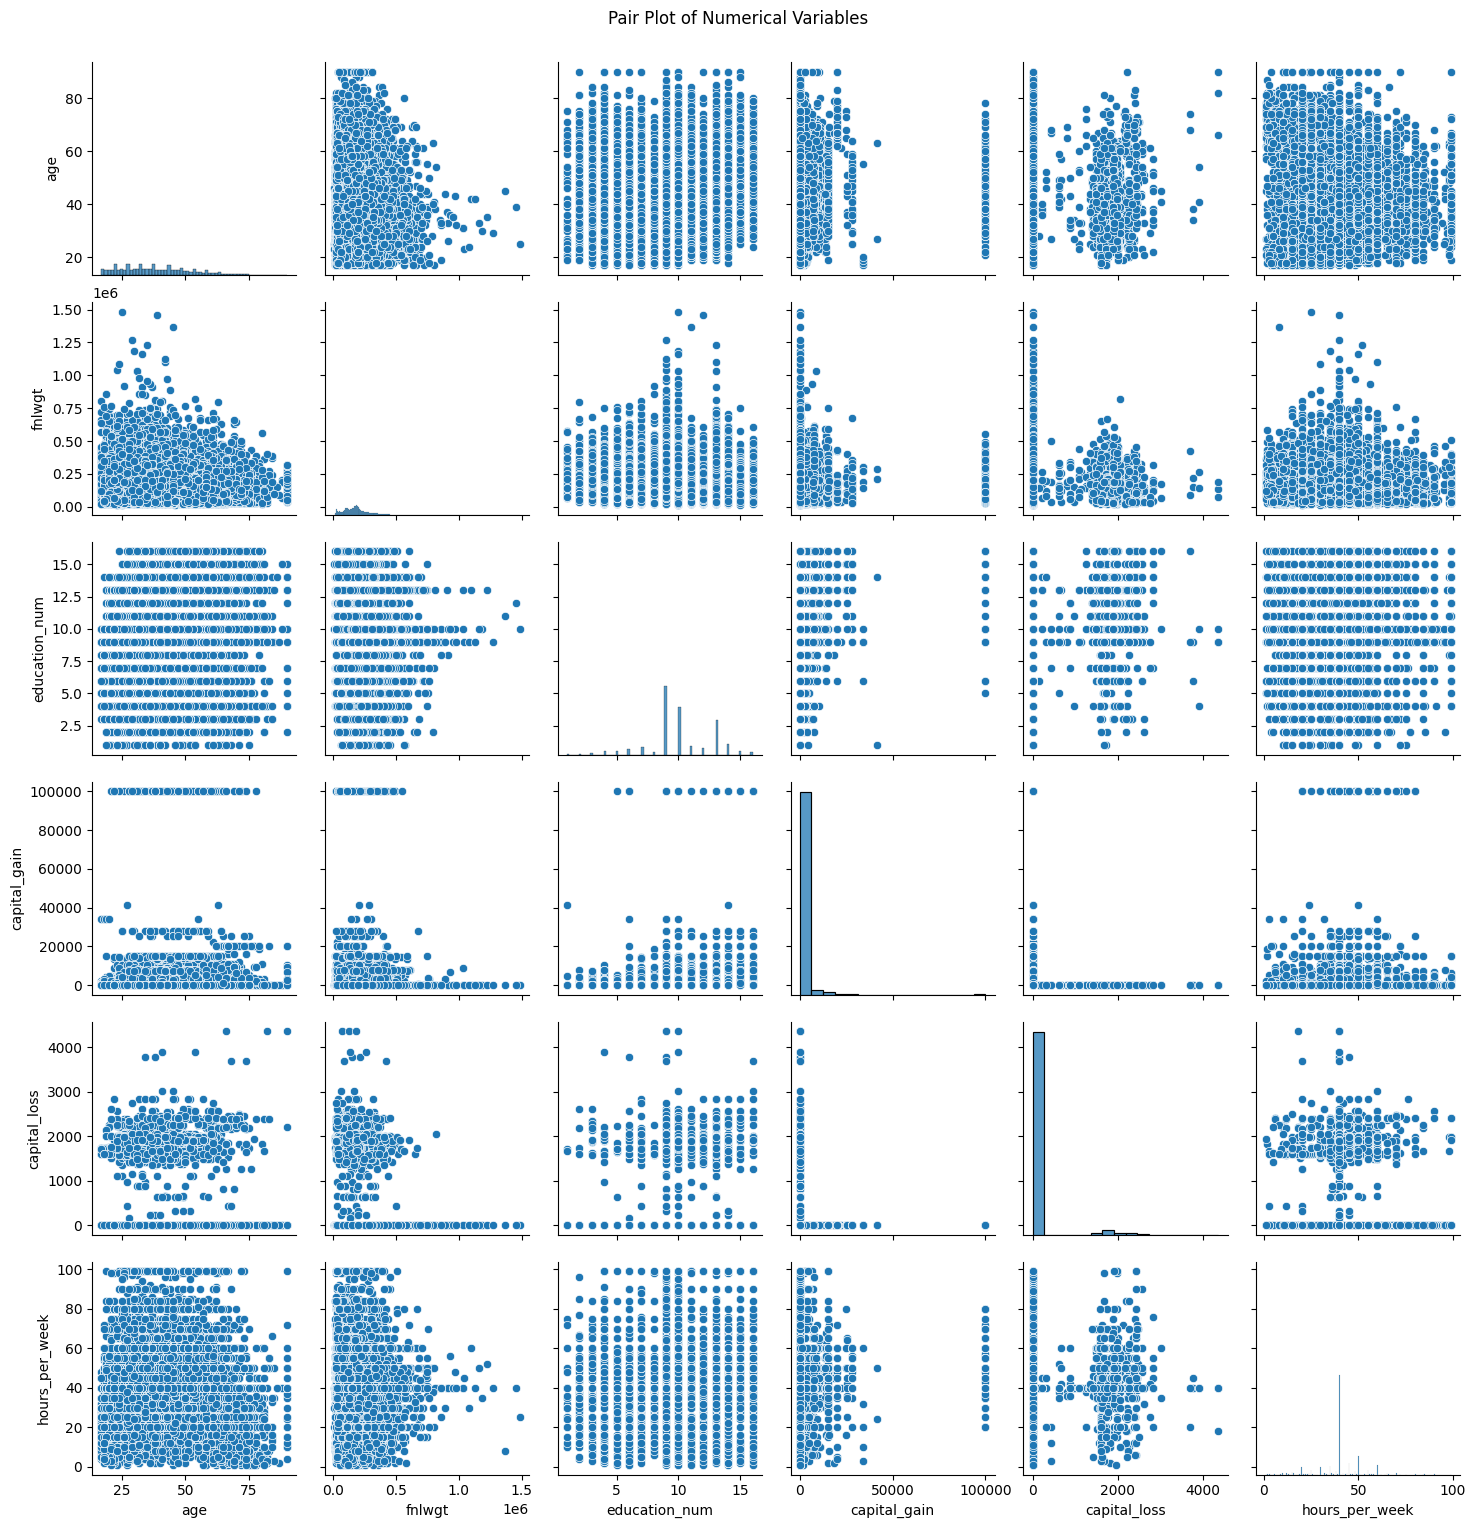

In [37]:
numerical_columns = ['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']
sns.pairplot(
    df[numerical_columns],
    diag_kind="hist"
)

plt.suptitle("Pair Plot of Numerical Variables", y=1.02)
plt.show()

The pair plot was used to examine the relationships and distributions among the numerical variables in the dataset. The plot shows that most numerical variables do not have a strong linear relationship with each other. Age and fnlwgt show a weak relationship, while education_num and hours_per_week show a slight positive relationship. Capital_gain and capital_loss are highly concentrated around zero, with a small number of higher values. The distribution of hours_per_week is mainly concentrated around the common working-hour range. Overall, the pair plot helps to identify patterns, distributions, and possible relationships among multiple numerical variables simultaneously.

# 7.4 Statistical Analysis
## 7.4.1 Mean, Median, Mode and Standard Deviation
 Statistical measures are used to summarize the numerical variables in the dataset. Mean represents the average value, median represents the middle value, mode represents the most frequently occurring value, and standard deviation measures the spread of the data around the mean.

In [38]:
statistics_summary = pd.DataFrame({
    "Mean": df[numerical_columns].mean(),
    "Median": df[numerical_columns].median(),
    "Mode": df[numerical_columns].mode().iloc[0],
    "Standard Deviation": df[numerical_columns].std()
})

statistics_summary

,Mean,Median,Mode,Standard Deviation
age,38.585549,37.0,36.0,13.637984
fnlwgt,189780.848511,178356.0,123011.0,105556.471009
education_num,10.081815,10.0,9.0,2.571633
capital_gain,1078.443741,0.0,0.0,7387.957424
capital_loss,87.368227,0.0,0.0,403.101833
hours_per_week,40.440329,40.0,40.0,12.346889


The statistical summary provides the mean, median, mode, and standard deviation of the numerical variables. The average age is about 38.59 years, with a median of 37 years. The average education level is about 10.08, while the average working hours are about 40.44 hours per week. Both capital_gain and capital_loss have a median and mode of zero, showing that most observations have no recorded capital gain or capital loss. The standard deviation values show that fnlwgt has a wide spread, while education_num has a relatively smaller variation.

## 7.4.2 Correlation Analysis
Correlation analysis is used to measure the strength and direction of the relationship between numerical variables. The correlation coefficient ranges from -1 to +1, where values close to +1 indicate a strong positive relationship, values close to -1 indicate a strong negative relationship, and values close to 0 indicate a weak relationship.


In [39]:
correlation_matrix = df[numerical_columns].corr()

correlation_matrix

,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week
age,1.000000,-0.076447,0.036224,0.077676,0.057745,0.068515
fnlwgt,-0.076447,1.000000,-0.043388,0.000429,-0.010260,-0.018898
education_num,0.036224,-0.043388,1.000000,0.122664,0.079892,0.148422
capital_gain,0.077676,0.000429,0.122664,1.000000,-0.031639,0.078408
capital_loss,0.057745,-0.010260,0.079892,-0.031639,1.000000,0.054229
hours_per_week,0.068515,-0.018898,0.148422,0.078408,0.054229,1.000000


The correlation analysis shows that most numerical variables have weak linear relationships with each other. The strongest positive correlation is between education_num and hours_per_week (0.148), followed by education_num and capital_gain (0.123). Age has a very weak positive correlation with capital_gain (0.078) and hours_per_week (0.069). Fnlwgt has weak negative correlations with age (-0.076) and education_num (-0.043). Overall, the correlation values are close to zero, indicating that there are no strong linear relationships among the numerical variables.


## 7.4.3 Percentage Analysis
 Percentage analysis is used to understand the proportion of observations in each income category. It helps to identify the distribution of income groups within the dataset.


In [40]:
income_percentage = (
    df["income"].value_counts(normalize=True)
    .mul(100)
    .round(2)
    .reset_index()
)

income_percentage.columns = ["income", "percentage"]

income_percentage


,income,percentage
0,<=50K,75.91
1,>50K,24.09


The percentage analysis shows the distribution of individuals across the two income categories. About 75.91% of the individuals belong to the <=50K income group, while 24.09% belong to the >50K income group. This indicates that the dataset contains a higher proportion of individuals earning $50,000 USD or less than those earning more than $50,000.

#7.5 Data Visualization
## Pie Chart
A pie chart is used to represent the proportion of individuals in each income category. It helps to visualize the percentage distribution of the <=50K and >50K income groups.


In [41]:
fig = px.pie(df, names="income", hole=0.4, title="Income Category Distribution (Plotly)")
fig.update_traces(textinfo="percent+label")
fig.show()

The pie chart shows the percentage distribution of individuals across the two income categories. About 75.91% of individuals belong to the <=50K income group, while 24.09% belong to the >50K income group. This indicates that the majority of individuals in the dataset earn $50,000 or less, whereas a smaller proportion earn more than $50,000. The chart clearly shows that the dataset contains a higher proportion of individuals in the <=50K income category.



# 7.6 Final Insights and Summary
The UCI Adult Income dataset was analyzed to understand the relationship between education, employment, demographic factors, and income levels. Data cleaning and preprocessing were performed before conducting exploratory data analysis, visualization, and statistical analysis.

The analysis revealed the following key insights:

1. *Income Distribution:* About 75.91% of individuals belong to the <=50K income group, while 24.09% belong to the >50K group.

2. *Education:* The analysis showed that individuals with higher education levels, such as a Bachelor's degree and Master's degree, were more represented in the >50K income category compared with lower education levels. This suggests an association between higher educational attainment and higher income levels in the dataset.

3. *Age:* The box plot showed that the >50K income group has a higher median age than the <=50K group.

4. *Working Hours:* Individuals in the >50K income group have higher average working hours per week than those in the <=50K group.

5. *Gender and Income:* The grouped bar plot showed differences in average working hours across gender and income categories.

6. *Correlation Analysis:* Most numerical variables showed weak linear correlations. Education level (education_num) had a small positive correlation with working hours (hours_per_week), approximately 0.15.

7. *Data Quality:* Missing values, duplicate records, inconsistent values, and potential outliers were examined during preprocessing. Potential outliers were retained for further analysis because extreme values may represent valid observations.

***Conclusion:***

This project demonstrated the use of Python libraries such as Pandas, NumPy, Matplotlib, and Seaborn for data cleaning, exploratory data analysis, statistical analysis, and visualization. The findings show patterns associated with income categories, but they do not establish that any single factor directly causes higher income.